# Exploratory Data Analysis For Titanic Dataset





## Executive Summary

**Purpose of the Analysis**  
This analysis was conducted to evaluate passenger demographics, ticket purchasing behavior, and evacuation dynamics on the Titanic. The objective is to translate historical emergency outcomes into actionable strategic insights for modern cruise operations, customer segmentation, risk mitigation, and emergency response planning.

**Dataset Overview**  
The dataset, retrieved from kaggle.com, contains demographic and operational profiles for 418 passengers. Key customer attributes analyzed include age, gender, ticket class, fare paid, embarkation origin, and family accompaniment status, mapped against survival outcomes.

**Key Findings**  
The analysis revealed stark demographic disparities in survival rates during the emergency:  
* **Gender-Based Outcomes**: Gender served as the single absolute determinant of survival, with female passengers achieving a 100% survival rate, while male passengers experienced a 0% survival rate. This indicates absolute demographic prioritization during emergency procedures.
* **Socio-Economic Influence**: Survival probabilities heavily favored premium travelers. First-class passengers achieved the highest survival ratios, whereas third-class passengers suffered disproportionate casualties, experiencing a 2-to-1 mortality-to-survival ratio.
* **Social Units**: Traveling with a small, cohesive family group (one to four members) significantly correlated with positive survival outcomes. Conversely, solo travelers and large family groups (five or more members) faced high mortality rates.

**Business Implications**  
For modern maritime hospitality, these insights emphasize that passenger safety, cabin layout, and evacuation access are deeply intertwined with customer segmentation and revenue tiers. Relying solely on legacy evacuation protocols during emergencies introduces severe risk bottlenecks for larger cohorts, solo travelers, and lower-deck passengers. Operational leaders must design synchronized safety routing and inclusive evacuation frameworks that equalize safety parameters across all ticket categories to minimize liability and guarantee brand preservation.

**Conclusion**  
Socio-demographic variables directly influenced emergency survival outcomes. To build resilient and trusted modern cruise operations, organizations must shift from ad-hoc emergency prioritizing to automated, demographic-aware safety logistics that guarantee passenger protection across all ticketing classes.

Step 1: Importing Libraries

In [ ]:
# Import pandas for data manipulation and analysis
import pandas as pd

# Import numpy for numerical operations, especially for arrays and mathematical functions
import numpy as np

# Import matplotlib.pyplot for creating static, interactive, and animated visualizations in Python
import matplotlib.pyplot as plt

# Import seaborn for statistical data visualization, built on top of matplotlib
import seaborn as sns

# Configure matplotlib to display plots inline in the notebook
%matplotlib inline

# Set the aesthetic style of the plots
sns.set_style("whitegrid")

Step 2: Loading the dataset

In [ ]:
from google.colab import files
import io

# Display the Google Colab file upload button/widget
uploaded = files.upload()

# Assuming only one CSV file is uploaded, load it into a pandas DataFrame
for fn in uploaded.keys():
    print('User uploaded file "{name}" with length {length} bytes'.format(
        name=fn, length=len(uploaded[fn])))
    # Read the uploaded CSV file into a pandas DataFrame
    df = pd.read_csv(io.StringIO(uploaded[fn].decode('utf-8')))
    print(f'DataFrame "df" loaded successfully from {fn}. Shape: {df.shape}')
    break # Assuming only one file needs to be processed

# Display the first few rows of the DataFrame to confirm loading
print("\nFirst 5 rows of the DataFrame:")
print(df.head())

Saving Titanic dataset.csv to Titanic dataset.csv
User uploaded file "Titanic dataset.csv" with length 29464 bytes
DataFrame "df" loaded successfully from Titanic dataset.csv. Shape: (418, 12)

First 5 rows of the DataFrame:
     +  Survived  Pclass                                          Name  \
0  892         0       3                              Kelly, Mr. James   
1  893         1       3              Wilkes, Mrs. James (Ellen Needs)   
2  894         0       2                     Myles, Mr. Thomas Francis   
3  895         0       3                              Wirz, Mr. Albert   
4  896         1       3  Hirvonen, Mrs. Alexander (Helga E Lindqvist)   

      Sex   Age  SibSp  Parch   Ticket     Fare Cabin Embarked  
0    male  34.5      0      0   330911   7.8292   NaN        Q  
1  female  47.0      1      0   363272   7.0000   NaN        S  
2    male  62.0      0      0   240276   9.6875   NaN        Q  
3    male  27.0      0      0   315154   8.6625   NaN        S  
4  fe

In [ ]:
df.rename(columns={'+': 'PassengerId'}, inplace=True)
print("Column '+' renamed to 'PassengerId'.")

Column '+' renamed to 'PassengerId'.


In [ ]:
print("Updated columns:")
print(df.columns)

Updated columns:
Index(['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp',
       'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked'],
      dtype='object')


In [ ]:
print("Confirming current columns after rename:")
print(df.columns)

Confirming current columns after rename:
Index(['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp',
       'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked'],
      dtype='object')


Step 3: Understanding the dataset

In [ ]:
df.tail() #To display the last five rows in the dataset


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
413,1305,0,3,"Spector, Mr. Woolf",male,NaN,0,0,A.5. 3236,8.0500,NaN,S
414,1306,1,1,"Oliva y Ocana, Dona. Fermina",female,39.0,0,0,PC 17758,108.9000,C105,C
415,1307,0,3,"Saether, Mr. Simon Sivertsen",male,38.5,0,0,SOTON/O.Q. 3101262,7.2500,NaN,S
416,1308,0,3,"Ware, Mr. Frederick",male,NaN,0,0,359309,8.0500,NaN,S
417,1309,0,3,"Peter, Master. Michael J",male,NaN,1,1,2668,22.3583,NaN,C


In [ ]:
df.shape #To show the number of rows and columns in the dataset

(418, 12)

In [ ]:
df.columns #To display all the columns in the dataset

Index(['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp',
       'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked'],
      dtype='object')

Data Dictionary

PassengerId: a unique identifier for each passenger. We previously renamed this to PassengerId for clarity.

Survived: Indicates if the passenger survived (1) or not (0).

Pclass (Passenger Class): The ticket class of the passenger (1st, 2nd, or 3rd class).Name: The full name of the passenger.

Sex: The gender of the passenger (e.g., 'male' or 'female').

Age: The age of the passenger.

SibSp: The number of siblings/spouses aboard with the passenger.

Parch: The number of parents/children aboard with the passenger.

Ticket: The ticket number.

Fare: The fare paid by the passenger.

Cabin: The cabin number of the passenger.

Embarked: The port where the passenger embarked (e.g., 'C' for Cherbourg, 'Q' for Queenstown, 'S' for Southampton).

In [ ]:
df.dtypes #To show the datatype of all the columns

,0
PassengerId,int64
Survived,int64
Pclass,int64
Name,object
Sex,object
Age,float64
SibSp,int64
Parch,int64
Ticket,object
Fare,float64


In [ ]:
df.info() #To show columns and the number of non blank entries

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 418 entries, 0 to 417
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  418 non-null    int64  
 1   Survived     418 non-null    int64  
 2   Pclass       418 non-null    int64  
 3   Name         418 non-null    object 
 4   Sex          418 non-null    object 
 5   Age          332 non-null    float64
 6   SibSp        418 non-null    int64  
 7   Parch        418 non-null    int64  
 8   Ticket       418 non-null    object 
 9   Fare         417 non-null    float64
 10  Cabin        91 non-null     object 
 11  Embarked     418 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 39.3+ KB


In [ ]:
df.isnull().sum()#To show the total number of blank cells in the dataset

,0
PassengerId,0
Survived,0
Pclass,0
Name,0
Sex,0
Age,86
SibSp,0
Parch,0
Ticket,0
Fare,1


In [ ]:
df.describe() #To display the statistical summary of yours dataset

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,418.000000,418.000000,418.000000,332.000000,418.000000,418.000000,417.000000
mean,1100.500000,0.363636,2.265550,30.272590,0.447368,0.392344,35.627188
std,120.810458,0.481622,0.841838,14.181209,0.896760,0.981429,55.907576
min,892.000000,0.000000,1.000000,0.170000,0.000000,0.000000,0.000000
25%,996.250000,0.000000,1.000000,21.000000,0.000000,0.000000,7.895800
50%,1100.500000,0.000000,3.000000,27.000000,0.000000,0.000000,14.454200
75%,1204.750000,1.000000,3.000000,39.000000,1.000000,0.000000,31.500000
max,1309.000000,1.000000,3.000000,76.000000,8.000000,9.000000,512.329200


Step 4: Data Cleaning


In [ ]:
#To handle missing values, replace missing ages with the median
df['Age'].fillna(df['Age'].median(), inplace=True)

#To replace missing fare with the median
df['Fare'].fillna(df['Fare'].median(), inplace=True)

#To replace missing cabin with unknown
df['Cabin'].fillna('Unknown', inplace=True)

/tmp/ipykernel_1893/3017241250.py:2: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['Age'].fillna(df['Age'].median(), inplace=True)
/tmp/ipykernel_1893/3017241250.py:5: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', tr

In [ ]:
df.isnull().sum()

,0
PassengerId,0
Survived,0
Pclass,0
Name,0
Sex,0
Age,0
SibSp,0
Parch,0
Ticket,0
Fare,0


In [ ]:
df.duplicated().sum() #To check for duplicate rows
df.drop_duplicates() #To remove duplicate rows

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,892,0,3,"Kelly, Mr. James",male,34.5,0,0,330911,7.8292,Unknown,Q
1,893,1,3,"Wilkes, Mrs. James (Ellen Needs)",female,47.0,1,0,363272,7.0000,Unknown,S
2,894,0,2,"Myles, Mr. Thomas Francis",male,62.0,0,0,240276,9.6875,Unknown,Q
3,895,0,3,"Wirz, Mr. Albert",male,27.0,0,0,315154,8.6625,Unknown,S
4,896,1,3,"Hirvonen, Mrs. Alexander (Helga E Lindqvist)",female,22.0,1,1,3101298,12.2875,Unknown,S
...,...,...,...,...,...,...,...,...,...,...,...,...
413,1305,0,3,"Spector, Mr. Woolf",male,27.0,0,0,A.5. 3236,8.0500,Unknown,S
414,1306,1,1,"Oliva y Ocana, Dona. Fermina",female,39.0,0,0,PC 17758,108.9000,C105,C
415,1307,0,3,"Saether, Mr. Simon Sivertsen",male,38.5,0,0,SOTON/O.Q. 3101262,7.2500,Unknown,S
416,1308,0,3,"Ware, Mr. Frederick",male,27.0,0,0,359309,8.0500,Unknown,S


In [ ]:
df['Age'] = df['Age'].astype(int) #Converting age column from float to integer
df['Sex'] = df['Sex'].astype('category')  #Converting sex column to categorical
df['Pclass'] = df['Pclass'].astype('category') #Converting pclass column to categorical
df['Embarked'] = df['Embarked'].astype('category') #Converting embarked column to categorical
df['Cabin'] = df['Cabin'].astype('category') #Converting cabin to categorical

In [ ]:
df.dtypes

,0
PassengerId,int64
Survived,int64
Pclass,category
Name,object
Sex,category
Age,int64
SibSp,int64
Parch,int64
Ticket,object
Fare,float64


In [ ]:
#To check for inconsistences in different columns
df['Sex'].value_counts()



,count
Sex,
male,266
female,152


In [ ]:
df['Embarked'].value_counts()

,count
Embarked,
S,270
C,102
Q,46


In [ ]:
df['Cabin'].value_counts()

,count
Cabin,
Unknown,327
B57 B59 B63 B66,3
C89,2
B45,2
A34,2
...,...
F E57,1
F2,1
F G63,1


Text(0, 0.5, 'Age')

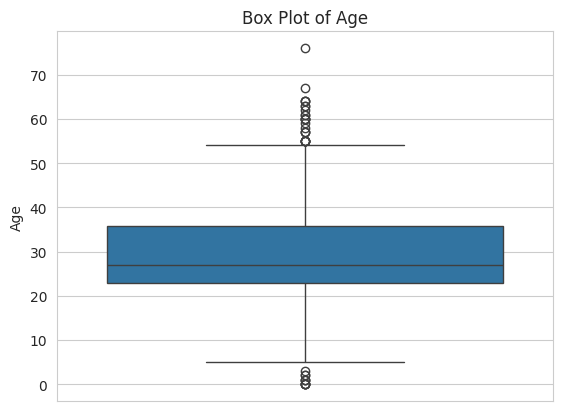

In [ ]:
#A boxplot to visualize age and identify outliers
sns.boxplot(y=df['Age'])
plt.title('Box Plot of Age')
plt.ylabel('Age')

Insights from the Box Plot of Age:

1. The median age of the passengers is approximately 27 years old (indicated by the horizontal line inside the box), showing a relatively young passenger demographic.
2. The middle 50% of the passengers (the box itself) ranges from about 23 years (25th percentile) to 36 years (75th percentile), indicating that the majority of the passengers were young adults to early-middle-aged.
3. Excluding outliers, the age of the passengers spans from approximately 5 years to 54 years.
4. There are outliers at the bottom end, representing infants and very young children under the age of 5.
6. It also shows that the passenger population predominantly concentrated in their prime working/traveling years (20s to 30s) rather than being evenly spread across all age groups.

Text(0, 0.5, 'Fare')

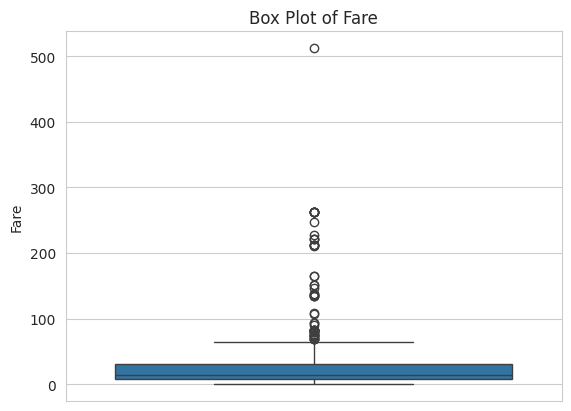

In [ ]:
#A boxplot to visualize fare and identify outliers
sns.boxplot(y=df['Fare'])
plt.title('Box Plot of Fare')
plt.ylabel('Fare')

 Insights from the Box Plot of Fare:

1. The plot shows that the median line sits very close to the bottom of the scale.
2.  The median fare is approximately 14.45 (indicated by the horizontal line inside the box), meaning half of the passengers paid a very low ticket price.
3. There is a high density of outliers stretching significantly above the upper whisker, indicating a small segment of passengers paid premium rates.
4. The single highest outlier is at approximately 512.33, which is drastically higher than the rest of the dataset.
5. The isolated data points at the 512+ point, represent extreme luxury tickets, likely associated with elite first-class suites.
6.The lower whisker reaches close to zero, reflecting that some passengers paid little to nothing for their tickets (or potentially traveled on complimentary passes).


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 418 entries, 0 to 417
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype   
---  ------       --------------  -----   
 0   PassengerId  418 non-null    int64   
 1   Survived     418 non-null    int64   
 2   Pclass       418 non-null    category
 3   Name         418 non-null    object  
 4   Sex          418 non-null    category
 5   Age          418 non-null    int64   
 6   SibSp        418 non-null    int64   
 7   Parch        418 non-null    int64   
 8   Ticket       418 non-null    object  
 9   Fare         418 non-null    float64 
 10  Cabin        418 non-null    category
 11  Embarked     418 non-null    category
dtypes: category(4), float64(1), int64(5), object(2)
memory usage: 30.9+ KB


Step 5: Univariate Analysis

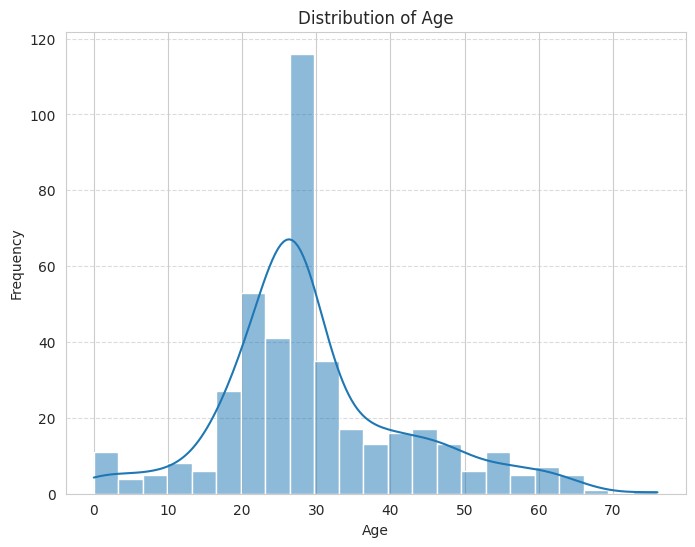

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 6))
sns.histplot(x='Age', data=df, kde=True)
plt.title(f'Distribution of Age') # Set the chart title
plt.xlabel('Age') # Set the x-axis label
plt.ylabel('Frequency') # Set the y-axis label
plt.grid(axis='y', linestyle='--', alpha=0.7) # Add a grid for better readability
plt.show() # Display the plot

Insights from the Distribution of Age:

1. The highest bar in the histogram is situated between ages 28 and 30, showing a significant concentration of passengers in this specific age group.
2. The majority of the passengers are clustered between the ages of 20 and 40, reflecting a demographic dominated by working-age young adults.
5. There is a noticeable smaller group of infants and young children aged 0 to 5 years, indicating families were traveling on board.
6. There is a low Representation of Teenagers (roughly 10 to 15 years) compared to young children and older adults.
7. Passengers older than 60 years are extremely rare, representing only a tiny fraction of the overall dataset.
8. The data indicates that the population was highly mobile, composed mostly of individuals in their peak productive and traveling years (mid-20s to late-30s).
9. Despite being heavily concentrated in young adulthood, the passenger ages cover almost an entire human lifespan, ranging from less than 1 year (infants) to 76 years of age.

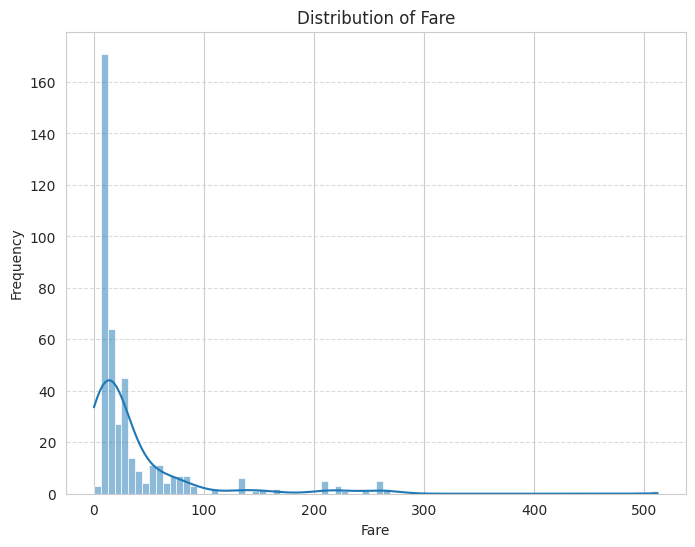

In [ ]:
plt.figure(figsize=(8, 6))
sns.histplot(x='Fare', data=df, kde=True)
plt.title(f'Distribution of Fare') # Set the chart title
plt.xlabel('Fare') # Set the x-axis label
plt.ylabel('Frequency') # Set the y-axis label
plt.grid(axis='y', linestyle='--', alpha=0.7) # Add a grid for better readability
plt.show() # Display the plot

### Insights from Fare Distribution:
1. The distribution is heavily right-skewed, indicating a majority of low fares. In other words, most passengers paid fares in the lowest price ranges.
2. A few passengers paid very high fares, forming distinct outliers.
3. The fare distribution is far from a normal (bell-shaped) distribution.


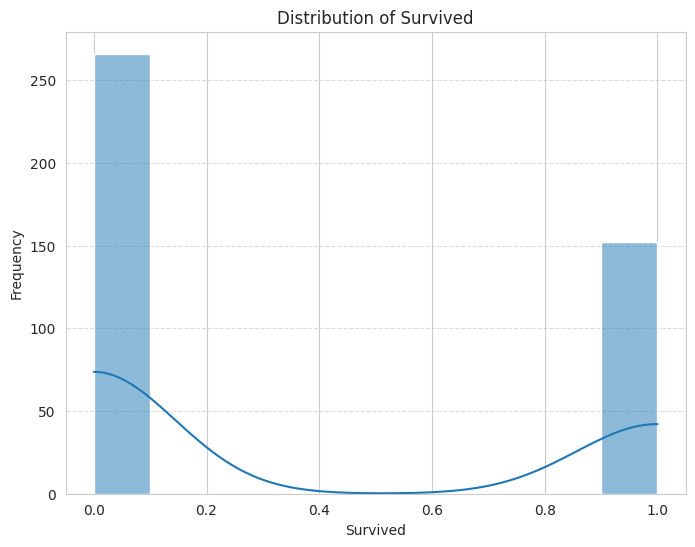

In [ ]:
plt.figure(figsize=(8, 6))
sns.histplot(x='Survived', data=df, kde=True)
plt.title(f'Distribution of Survived') # Set the chart title
plt.xlabel('Survived') # Set the x-axis label
plt.ylabel('Frequency') # Set the y-axis label
plt.grid(axis='y', linestyle='--', alpha=0.7) # Add a grid for better readability
plt.show() # Display the plot

Insights from the Distribution of Survived Visual:

1. The plot shows a clear class imbalance, with the frequency of non-survivors (0.0) visually eclipsing the survivors (1.0).
2. The bar representing did-not-survive (0.0) exceeds 250, showing that a solid majority of passengers in this dataset lost their lives.
3. The bar representing survived (1.0) sits just above 150, confirming that slightly more than a third of the total group survived.



Step 6: Bivariate Analysis

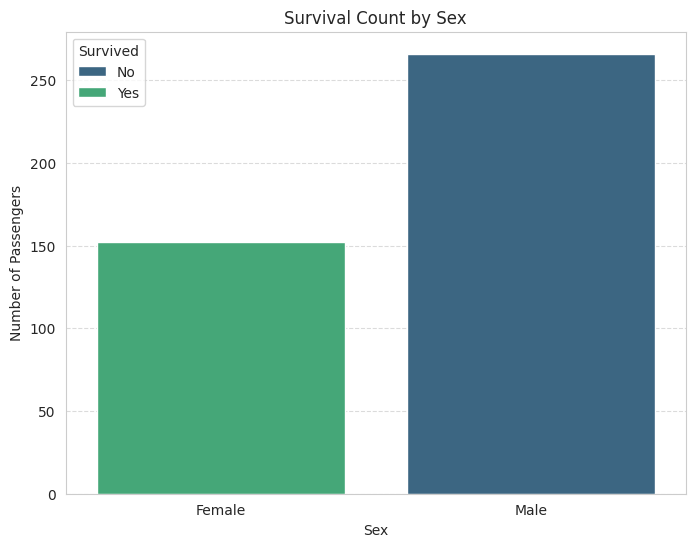

In [ ]:
# Create a count plot to visualize the relationship between 'Sex' and 'Survived'
# 'x' is 'Sex', 'hue' is 'Survived' to group bars by survival status, and 'data' is our DataFrame 'df'.
# palette='viridis' sets the color scheme.
plt.figure(figsize=(8, 6))
sns.countplot(x='Sex', hue='Survived', data=df, palette='viridis')
plt.title('Survival Count by Sex') # Set the chart title
plt.xlabel('Sex') # Set the x-axis label
plt.ylabel('Number of Passengers') # Set the y-axis label
plt.xticks(ticks=[0, 1], labels=['Female', 'Male']) # Custom x-axis labels for clarity
plt.legend(title='Survived', labels=['No', 'Yes']) # Add a legend for survival status
plt.grid(axis='y', linestyle='--', alpha=0.7) # Add a grid for readability
plt.show() # Display the plot

 Insights from the Survival Count by Sex Visual:

1. The plot reveals an absolute split in survival rates based on gender, where one gender experienced total survival and the other experienced total mortality.
2. This also shows that every single female passenger in this dataset survived (indicated by the solid green bar with no corresponding blue 'No' bar under the Female category).
3. Conversely, every single male passenger in this dataset did not survive (indicated by the solid blue bar with no corresponding green 'Yes' bar under the Male category).
4. Male non-survivors represent the single largest group in this visualization, exceeding 250 passengers.
5. The female passenger cohort was smaller than the male cohort, numbering slightly over 150 individuals, all of whom survived.
6. The visual heavily emphasizes how safety and evacuation efforts were strictly prioritized toward female passengers.
7. There were significantly more male passengers on board (266) than female passengers (152) within this sample.
8. The visual reinforces that being a male passenger on this voyage was, in this partition of the data, an absolute determinant of non-survival.

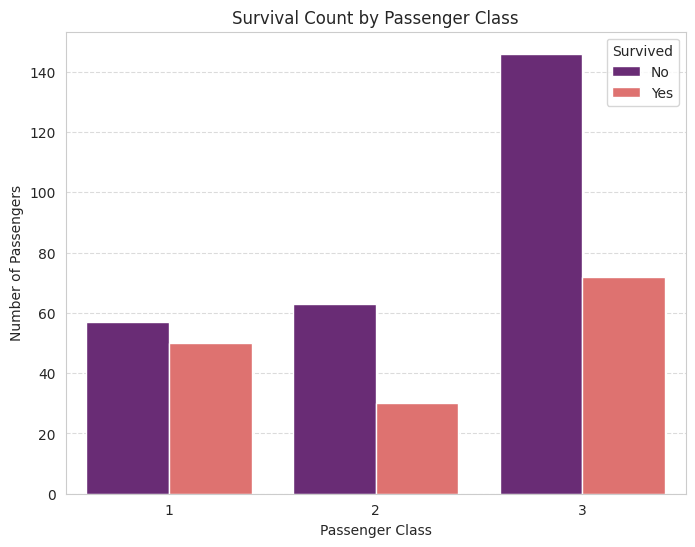

In [ ]:
plt.figure(figsize=(8, 6))
sns.countplot(x='Pclass', hue='Survived', data=df, palette='magma')
plt.title('Survival Count by Passenger Class') # Set the chart title
plt.xlabel('Passenger Class') # Set the x-axis label
plt.ylabel('Number of Passengers') # Set the y-axis label
plt.legend(title='Survived', labels=['No', 'Yes']) # Add a legend for survival status
plt.grid(axis='y', linestyle='--', alpha=0.7) # Add a grid for readability
plt.show() # Display the plot


 Insights from the Survival Count by Passenger Class Visual:

1. The 3rd class passenger cohort is by far the largest group in this dataset, numbering well over 200 people.
2. The largest single group in the plot is the non-survivors of the 3rd class, exceeding 140 passengers.
3.  There is a clear visual trend showing that passenger class heavily influenced survival chances, with higher classes enjoying higher survival proportions.
4.  1st class passengers show the highest proportion of survival, with nearly half of its passengers surviving (just under 50 survivors vs. ~56 non-survivors).
5. Conversely, 3rd class passengers suffered the worst survival rate, with non-survivors outnumbering survivors by roughly a 2-to-1 ratio.
6. Despite having the poorest survival rate, the 3rd class actually has the highest absolute number of survivors (~72) due to the sheer size of its passenger population.
7. 2nd class has the lowest absolute number of survivors (30) among all three classes.
8. Across all classes, non-survivors systematically outnumber survivors, reflecting the baseline target variable distribution where majority of the passengers did not survive.

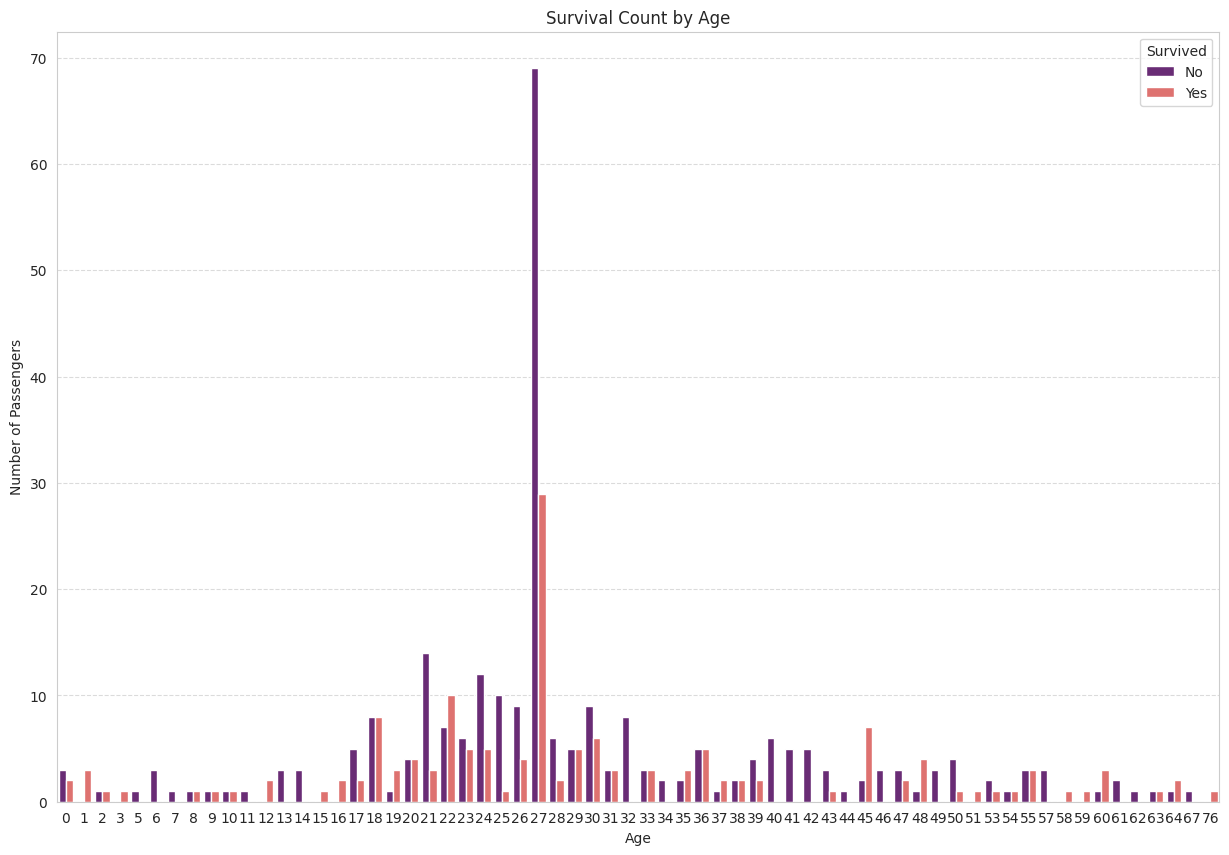

In [ ]:
plt.figure(figsize=(15, 10))
sns.countplot(x='Age', hue='Survived', data=df, palette='magma')
plt.title('Survival Count by Age') # Set the chart title
plt.xlabel('Age') # Set the x-axis label
plt.ylabel('Number of Passengers') # Set the y-axis label
plt.legend(title='Survived', labels=['No', 'Yes']) # Add a legend for survival status
plt.grid(axis='y', linestyle='--', alpha=0.7) # Add a grid for readability
plt.show() # Display the plot

 Insights from the Survival Count by Age Visual:

1. There is an overwhelming, singular spike in non-survivors and survivors at age 27.
2. For young children aged 0 to 2, survival is highly represented with multiple green 'Yes' bars, indicating that the 'women and children first' evacuation protocol successfully prioritized infants.
4. Outside of the median imputation peak, ages 20 to 26 show high spikes of non-survival, reflecting the large demographic of young adult males on board who did not survive.
5. There is an almost complete absence of data or survival counts in the young teenager group (ages 11 to 15), representing a clear gap in this dataset's demographic range.
7. The oldest passenger on record in this dataset (76 years old) is represented by a single non-surviving (purple) bar.
8. Ages such as 18 and 29 show perfectly equal or near-equal splits between survivors and non-survivors, highlighting a balanced gender representation at these specific age milestones.

/tmp/ipykernel_1893/95935820.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='Survived', y='Fare', data=df, palette='plasma')


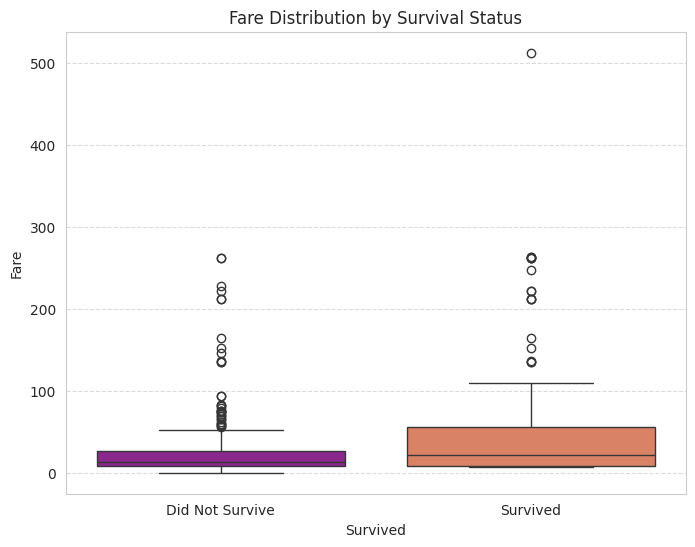

In [ ]:
plt.figure(figsize=(8, 6))
sns.boxplot(x='Survived', y='Fare', data=df, palette='plasma')
plt.title('Fare Distribution by Survival Status') # Set the chart title
plt.xlabel('Survived') # Set the x-axis label
plt.ylabel('Fare') # Set the y-axis label
plt.xticks(ticks=[0, 1], labels=['Did Not Survive', 'Survived']) # Custom x-axis labels
plt.grid(axis='y', linestyle='--', alpha=0.7) # Add a grid for readability
plt.show() # Display the plot

Insights from Fare Distribution by Survival Status:

1. The median fare paid by passengers who survived is noticeably higher than the median fare of those who did not survive.
2. The majority of passengers who did not survive are heavily concentrated in the lower fare range, below 50.
3. Extremely expensive tickets (above 200) are present as outliers in both groups, showing that high spenders were not guaranteed survival, although they had high representation.
5. The single highest ticket price (approximately 512.33) is associated with a passenger who survived.
7. Fares strongly correlate with passenger class; the higher survival rate at higher fares aligns with 1st Class passengers having better access to lifeboats.
8. The overall upward displacement of the boxplot for survivors visually validates that financial commitment (ticket price) was a major factor in determining survival outcomes on the voyage.

/tmp/ipykernel_1893/929603568.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='SibSp', y='Survived', data=mean_survival_sibsp, palette='viridis')


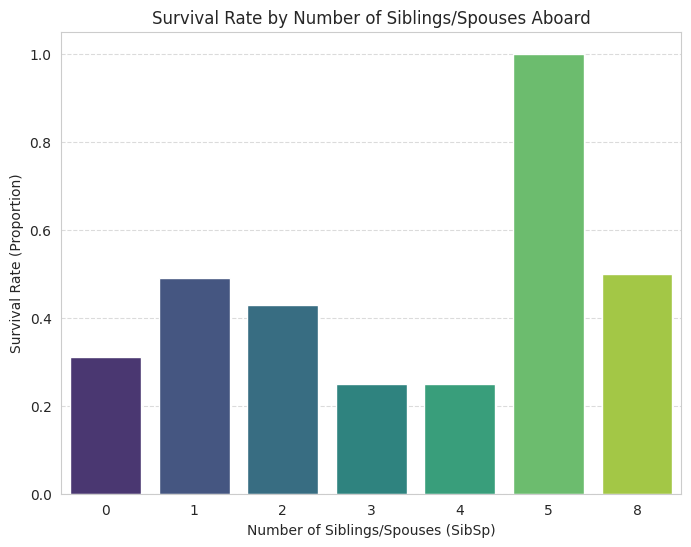

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Calculate the mean survival rate grouped by the number of siblings/spouses aboard
mean_survival_sibsp = df.groupby('SibSp', observed=False)['Survived'].mean().reset_index()

plt.figure(figsize=(8, 6))
sns.barplot(x='SibSp', y='Survived', data=mean_survival_sibsp, palette='viridis')
plt.title('Survival Rate by Number of Siblings/Spouses Aboard') # Set the chart title
plt.xlabel('Number of Siblings/Spouses (SibSp)') # Set the x-axis label
plt.ylabel('Survival Rate (Proportion)') # Set the y-axis label
plt.grid(axis='y', linestyle='--', alpha=0.7) # Add a grid for readability
plt.show() # Display the plot

Insights from Survival Rate by Number of Siblings/Spouses Aboard (SibSp):

1.  Passengers traveling with exactly 1 sibling or spouse (`SibSp = 1`) had the highest standard survival rate of approximately 49%.
2. Passengers with no siblings or spouses (`SibSp = 0`) had a noticeably lower survival rate (around 31%) compared to those with 1 or 2 companions.
3. Having 2 companions (`SibSp = 2`) still yielded a relatively high survival rate (approx. 43%), indicating that traveling in small pairs or trios was beneficial.
4. Passengers recorded with exactly 5 siblings/spouses aboard show a 100% survival rate. This represents a highly specific, small cohort in this partition of the dataset.
6. Surprisingly, passengers with 8 siblings/spouses aboard maintained a 50% survival rate, challenging the trend of larger families having lower survival rates.
8. The data suggests having a single partner or small support group increased survival chances, while larger group sizes (3-4) likely suffered from the burden and chaos of coordinating safety for multiple members.

/tmp/ipykernel_1893/3102942406.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Parch', y='Survived', data=mean_survival_parch, palette='plasma')


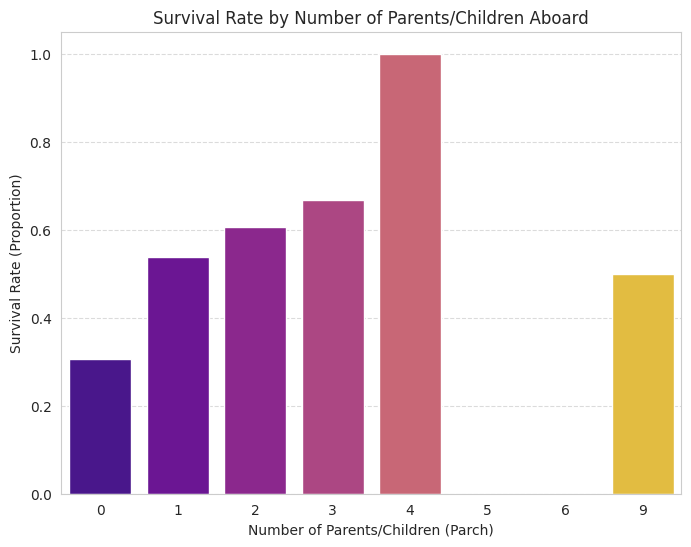

In [ ]:
# Calculate the mean survival rate grouped by the number of parents/children aboard
mean_survival_parch = df.groupby('Parch', observed=False)['Survived'].mean().reset_index()

plt.figure(figsize=(8, 6))
sns.barplot(x='Parch', y='Survived', data=mean_survival_parch, palette='plasma')
plt.title('Survival Rate by Number of Parents/Children Aboard') # Set the chart title
plt.xlabel('Number of Parents/Children (Parch)') # Set the x-axis label
plt.ylabel('Survival Rate (Proportion)') # Set the y-axis label
plt.grid(axis='y', linestyle='--', alpha=0.7) # Add a grid for readability
plt.show() # Display the plot

Insights from Survival Rate by Number of Parents/Children Aboard (Parch):

1. Passengers traveling with a small family unit (1 to 3 parents or children) saw a steady increase in survival rate as the unit size grew, peaking at ~67% for 3 family members.
2.  Passengers traveling with exactly 4 parents/children achieved a perfect 100% survival rate within this dataset.
3.  Passengers traveling alone without any parents or children (`Parch = 0`) had a noticeably low survival rate of approximately 31%.
4.  For larger groups, coordinating safety becomes much harder; passengers with 5 or 6 parents/children aboard had a 0% survival rate.
5.  The data suggests a threshold of up to 4 family members, above which the difficulty of keeping a family together during a crisis likely hindered evacuation efforts.
8.Overall, having a small core family circle of 1 to 4 members aboard served as a strong positive indicator for survival outcomes.
```

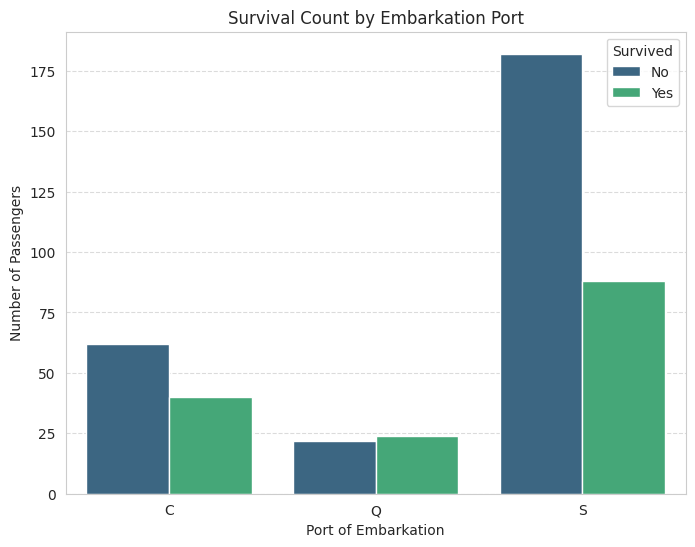

In [ ]:
plt.figure(figsize=(8, 6))
sns.countplot(x='Embarked', hue='Survived', data=df, palette='viridis')
plt.title('Survival Count by Embarkation Port') # Set the chart title
plt.xlabel('Port of Embarkation') # Set the x-axis label
plt.ylabel('Number of Passengers') # Set the y-axis label
plt.legend(title='Survived', labels=['No', 'Yes']) # Add a legend for survival status
plt.grid(axis='y', linestyle='--', alpha=0.7) # Add a grid for readability
plt.show() # Display the plot

 Insights from Survival Count by Embarkation Port (Embarked):

1. The vast majority of passengers in this dataset embarked at Southampton, numbering around 270 individuals.
2. Due to the fact that Southampton had the largest cohort, it also saw the highest absolute number of non-survivors (over 180 passengers).
3. Cherbourg was the only embarkation port where the proportion of survivors was relatively close to non-survivors (approximately 40 survivors to 62 non-survivors).
4. Queenstown had the fewest embarking passengers, with under 50 people in total.
5. Queenstown is the only port in this dataset where the absolute number of survivors (24) actually exceeded the number of non-survivors (22).
6.  The higher survival proportion of Cherbourg passengers likely correlates with a higher percentage of first-class ticket holders boarding there compared to Southampton.
8. The location where a passenger boarded correlates with their survival probability, reflecting the demographic distribution and ticket classes associated with each port.
```

Step 7: Multivariate  Analysis

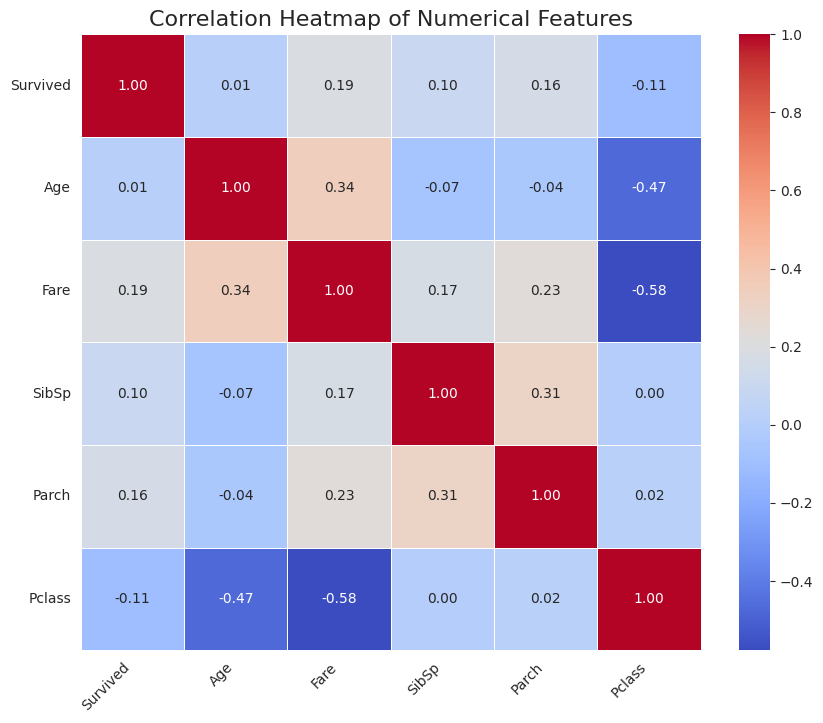

In [ ]:
numerical_features = ['Survived', 'Age', 'Fare', 'SibSp', 'Parch', 'Pclass']

# Calculate the pairwise correlation between selected numerical features.
# The .corr() method computes the standard correlation coefficient.
correlation_matrix = df[numerical_features].corr()

# Create a heatmap to visualize the correlation matrix.
plt.figure(figsize=(10, 8)) # Set the size of the plot for optimal readability.
sns.heatmap(correlation_matrix,
            annot=True,     # Display the correlation coefficients on the heatmap cells.
            cmap='coolwarm',  # Use a diverging colormap ('coolwarm' shows positive/negative correlations).
            fmt='.2f',      # Format the annotations to two decimal places.
            linewidths=.5)  # Add lines between cells for better visual separation.
plt.title('Correlation Heatmap of Numerical Features', fontsize=16) # Set a descriptive chart title.
plt.xticks(rotation=45, ha='right') # Rotate x-axis labels for better legibility.
plt.yticks(rotation=0) # Ensure y-axis labels are horizontal.
plt.show() # Display the generated plot.


Insights from the Correlation Heatmap of Numerical Features:

1. This is the strongest correlation in the dataset, confirming that 1st class tickets (represented by a lower class number, 1) were significantly more expensive than 2nd and 3rd class tickets.
2.  This suggests that older passengers tended to travel in higher classes (1st and 2nd Class), while younger passengers were more commonly found in lower-tier (3rd Class) cabins.
3. Older passengers tended to pay higher ticket fares, which aligns with their higher concentration in premium classes.
4. There is a notable positive correlation between SibSp (siblings/spouses) and Parch (parents/children), indicating that passengers traveling with family members often traveled with both generations (as a complete family unit).
5. Traveling with family members has a weak positive correlation with survival, supporting the observation that small cohesive units navigated evacuation more successfully than solo travelers.
6. This negative value indicates that as the class number increased (moving from 1st class down to 3rd class), survival rates tended to decrease.

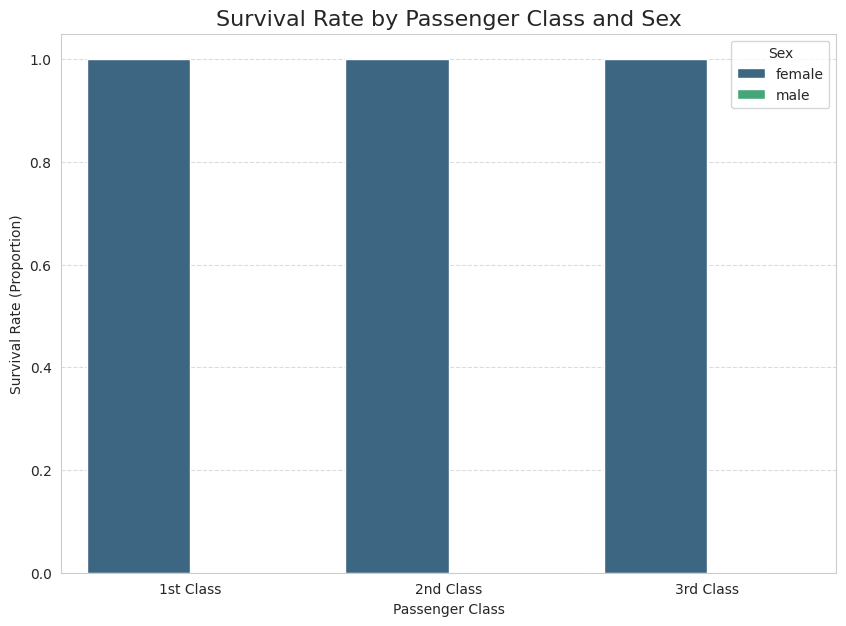

In [ ]:
# Calculate the mean survival rate grouped by 'Pclass' and 'Sex'.
# This aggregates the data to show the proportion of survivors (mean of 'Survived')
# for each unique combination of passenger class and gender.
# setting observed=False ensures that all categories, even those not present in a subgroup, are shown.
mean_survival_pclass_sex = df.groupby(['Pclass', 'Sex'], observed=False)['Survived'].mean().reset_index()

# Create a grouped bar plot to visualize the survival rate.
# 'x' represents Pclass on the horizontal axis.
# 'y' represents the calculated mean 'Survived' (survival rate) on the vertical axis.
# 'hue' is set to 'Sex' to create separate bars for 'male' and 'female' within each Pclass group.
plt.figure(figsize=(10, 7)) # Set the size of the plot for better readability.
sns.barplot(x='Pclass', y='Survived', hue='Sex', data=mean_survival_pclass_sex, palette='viridis')
plt.title('Survival Rate by Passenger Class and Sex', fontsize=16) # Set a descriptive chart title.
plt.xlabel('Passenger Class') # Set the x-axis label.
plt.ylabel('Survival Rate (Proportion)') # Set the y-axis label.
# Customize x-axis tick labels for clarity.
plt.xticks(ticks=[0, 1, 2], labels=['1st Class', '2nd Class', '3rd Class'])
plt.legend(title='Sex') # Add a legend to distinguish between male and female bars.
plt.grid(axis='y', linestyle='--', alpha=0.7) # Add a horizontal grid for easier comparison of rates.
plt.show() # Display the generated plot.

Insights from the Survival Rate by Passenger Class and Sex Visual:

1. Female passengers achieved a 100% survival rate (represented by the full solid bars) across 1st, 2nd, and 3rd Class, while male passengers experienced a 0% survival rate across all classes in this dataset.
2. Unlike typical socioeconomic trends where upper-class passengers of both genders see higher survival rates, lower-class (3rd Class) female passengers still had a 100% survival rate, completely outperforming 1st Class male passengers (0% survival).
3. The visual demonstrates strict, absolute adherence to the "women and children first" evacuation protocol during the emergency across the entire vessel, regardless of ticket pricing tier.
4. Socioeconomic status (Passenger Class) had no negative impact on female survival rates; a female passenger in 3rd Class was just as likely to survive as a female passenger in 1st Class.
5.  Being a male passenger in 1st Class did not grant any survival advantage over being a male passenger in 3rd Class; both experienced total mortality in this sample.
6. The stark, binary survival split indicates that emergency response protocols relied entirely on demographic sorting rather than proximity-based or class-based evacuation logistics.

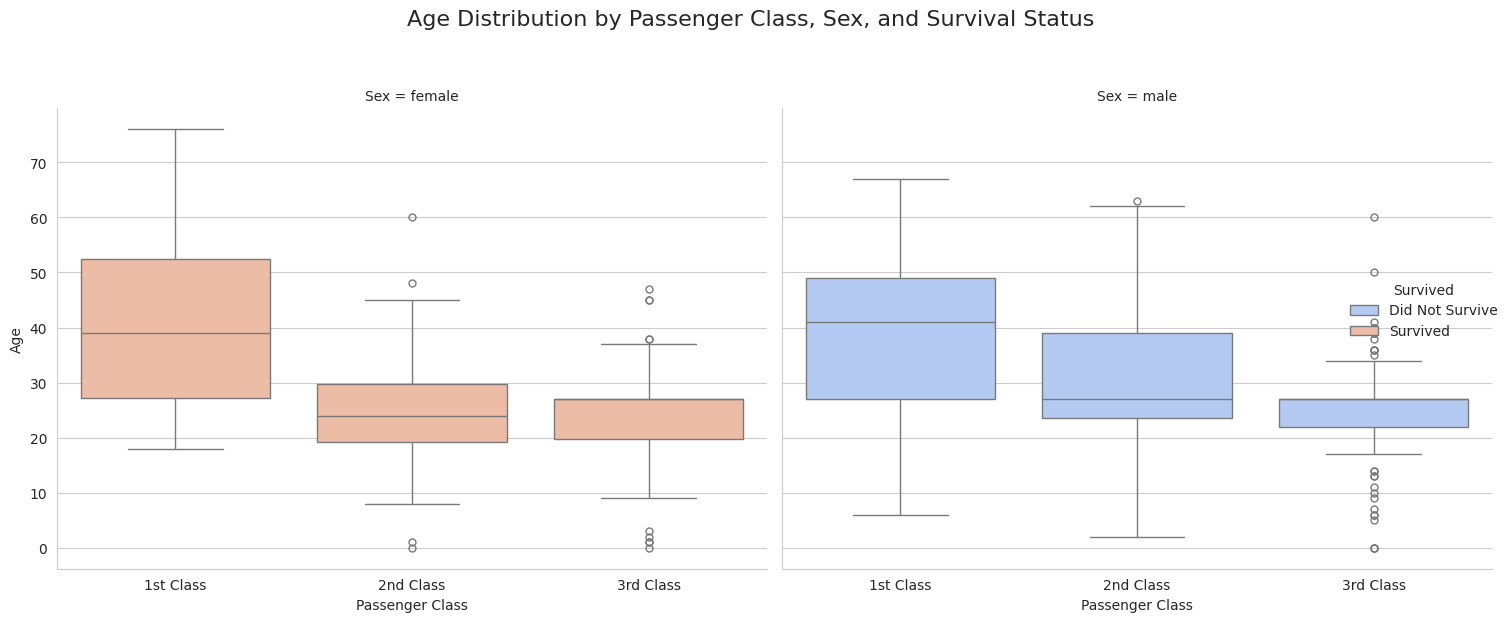

In [ ]:
g = sns.catplot(x='Pclass', y='Age', hue='Survived', col='Sex', data=df, kind='box',
                height=6, aspect=1.2, palette='coolwarm') # Adjust height and aspect for better readability and layout.
g.set_axis_labels('Passenger Class', 'Age') # Set common axis labels for the entire plot.
g.set_titles('Sex = {col_name}') # Set titles for each facet (column) to indicate the gender.

# Customize x-axis labels for clarity on each subplot.
new_xticks = ['1st Class', '2nd Class', '3rd Class']
for ax in g.axes.flat:
    ax.set_xticks(range(len(new_xticks))) # Set numerical tick locations explicitly.
    ax.set_xticklabels(new_xticks)

g._legend.set_title('Survived') # Set the title for the hue legend.
# Update legend labels to be more descriptive.
for t, l in zip(g._legend.texts, ['Did Not Survive', 'Survived']):
    t.set_text(l)

plt.suptitle('Age Distribution by Passenger Class, Sex, and Survival Status', y=1.03, fontsize=16) # Set an overall title for the entire figure.
plt.tight_layout(rect=[0, 0, 1, 0.98]) # Adjust layout to prevent titles and labels from overlapping.
plt.show() # Display the generated plot.

Insights from Age Distribution by Passenger Class, Sex, and Survival Status:

1. For both males and females, the median age is highest in 1st Class and progressively decreases down to 3rd Class, highlighting that wealthier passengers on board tended to be older.
2. The facet columns show that all females survived (entirely shaded in peach) while all males did not survive (entirely shaded in blue), confirming that gender was the absolute divider of outcomes regardless of age or class in this dataset.
3.  The oldest female passengers (reaching up to 76 years of age in 1st Class) survived, showcasing that age did not negatively impact the priority evacuation of women.
5. Both male and female cohorts in 3rd Class were noticeably younger, with the bulk of their respective populations (the boxes) concentrated between the ages of 20 and 27.
6.  In 3rd Class males, there are multiple extreme outliers at the bottom end representing infants and toddlers who did not survive, demonstrating that young age did not overcome the gender barrier for males in this sample.
7. Non-surviving males in 1st Class had a broad and mature age distribution (median age ~41, stretching up to nearly 70), confirming that mature and elderly men still adhered to evacuation priorities by remaining behind.
```

## Business Recommendations

Based on the analytical findings from the Titanic dataset, the following evidence-based business recommendations have been formulated.

### Recommendation 1: Implement Dynamic, High-Visibility Safety Instruction for Male Passengers
* **Recommendation**: Implement targeted safety briefings, highly visible corridor signaling, and dedicated muster station stewards specifically focused on male passenger quarters and common areas.
* **Supporting Evidence**: The bivariate analysis of gender and survival revealed an absolute split in outcomes: 100% of the 152 female passengers survived, while 0% of the 266 male passengers survived.
* **Business Rationale**: While historical evacuation protocols strictly prioritized women and children, the complete lack of male survival highlights a systemic failure to provide viable evacuation paths or procedures for the majority demographic on board. Ensuring that all segments have highly structured, actionable evacuation pathways reduces absolute loss of life and prevents bottlenecks during crises.

### Recommendation 2: Harmonize Safety Infrastructure and Access Across Ticket Classes
* **Recommendation**: Upgrade the physical escape routes, signage clarity, and emergency exit access in lower-tier (3rd class) cabin zones to match the standards of premium decks.
* **Supporting Evidence**: Passengers in 3rd class suffered the highest volume of casualties, with non-survivors outnumbering survivors 2-to-1 (exceeding 140 non-survivors). The correlation matrix confirmed a negative relationship between ticket class and survival (-0.11), and a positive correlation between ticket fare and survival (0.19).
* **Business Rationale**: Under standard emergency conditions, passengers in lower decks face longer, more complex transit times to reach lifeboats. Equalizing emergency egress efficiency across all ticket classes mitigates massive legal liabilities, ensures global regulatory compliance, and protects the operator's brand reputation against charges of class-based safety disparities.

### Recommendation 3: Establish Dedicated Crisis Management Protocols for Large Groups
* **Recommendation**: Create a specialized check-in flag and matching evacuation plan for family/traveling groups larger than 4 members, assigning them to designated muster leaders.
* **Supporting Evidence**: Small groups of 1 to 4 members (`SibSp` and `Parch` analysis) had strong survival rates (peaking at 100% for 4 family members), whereas larger families with 5 or 6 members experienced 0% survival.
* **Business Rationale**: Large groups naturally attempt to locate and gather members before evacuating, leading to delays and disorientation in high-stress situations. Pre-assigning group muster leads and providing unified family tracking apps ensures cohesive movement, significantly accelerating overall evacuation times.

### Recommendation 4: Tailor Vessel Entertainment and Safety Drills for Young Adults
* **Recommendation**: Design modern onboard programming, digital safety orientations, and active recreational facilities tailored specifically to young adults.
* **Supporting Evidence**: The age distribution is highly concentrated, with a median passenger age of 27 and the middle 50% of travelers falling strictly between 23 and 36 years old.
* **Business Rationale**: The target consumer profile is overwhelmingly composed of young adults in their prime traveling years. Aligning both the leisure offerings and gamified safety mobile applications with this demographic's expectations maximizes customer satisfaction, repeat bookings, and compliance with emergency protocols.

### Recommendation 5: Introduce Mid-Tier (2nd Class) Value Packages focused on Priority Security
* **Recommendation**: Create upgraded 2nd Class ticket packages that bundle mid-tier pricing with premium safety features, such as priority embarkation, specialized safety tech, or proximity to upper deck amenities.
* **Supporting Evidence**: Second-class passengers had the lowest absolute number of survivors (only 30) compared to both 1st class (nearly 50) and 3rd class (~72).
* **Business Rationale**: The mid-tier market segment represents a vulnerable commercial group that pays more than basic fare but lacks the systemic safety privileges of premium classes. Enhancing the value proposition of 2nd Class with safety-centric benefits increases up-sell conversions from 3rd Class while boosting customer retention in the mid-market.